#Imports

In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import norm, chi2
from enum import Enum

#Part A: The Casino's Edge (LLN and CLT)

&nbsp;


Initialising Variables

&nbsp;


In [ ]:
N : int = 1000                                                                  #players
GAMES : int = 1000                                                              #ames
PROB = [0.1, 0.2, 0.0]                                                          #[r, b, 0.0]
PROB[2] = 1 - (PROB[1] + PROB[0])
CASINO_DIST = [18, 18, 2]                                                       #Slots
CASINO_PROB = [float(x) / sum(CASINO_DIST) for x in CASINO_DIST]                #occurance probabs

In [ ]:
class Color(Enum) :                                                             #im generating the roulette outcome
  RED   = 0
  BLACK = 1
  GREEN = 2

def play() -> int:
  elements : list[Color] = [Color.RED, Color.BLACK, Color.GREEN]
  chosen : Color = np.random.choice(elements, 1, p = PROB)
  outcome : Color = np.random.choice(elements, 1, p = CASINO_PROB)

  if outcome == chosen:
    return 1
  return -1


&nbsp;


1\) Simulating bankroll for one person and 1000 games

&nbsp;


In [ ]:
cumsum = [0 for _ in range(GAMES + 1)]
for game in range(1, GAMES + 1):
  cumsum[game] = cumsum[game - 1] + play()

&nbsp;


2 a) Plotting Bankroll trajectory (cumsum[$n$]) vs $n$.

&nbsp;



Bankroll = -642
E[Bankroll] = -642.1052631578947


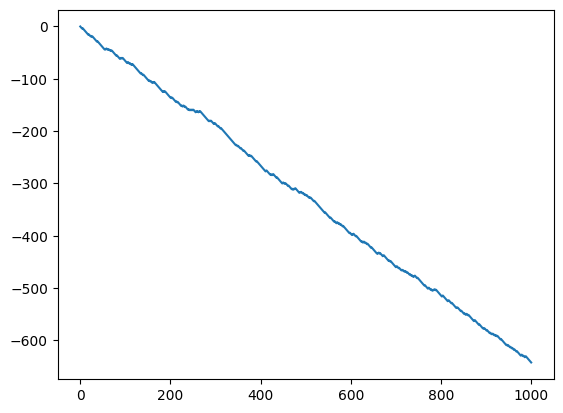

In [ ]:
sns.lineplot(cumsum)

print(f"Bankroll = {cumsum[-1]}")                                               #Total Experimental payoff
print(f"E[Bankroll] = {GAMES * (32 * (PROB[0] + PROB[1]) - 34) / 38.0}")        #Total Expected payoff

&nbsp;

It generally trends downward since the expected payoff for a single round is negative. We prove this as follows:

&nbsp;

Let Payoff for a single round be $P$

$E[P]=E[P|r]\cdot r + E[P|b]\cdot b + E[P|g]\cdot (1-r-b)$

&nbsp;

Substituting variable values, we get:

$E[P]= \frac{32}{38}(r+b) - \frac{34}{38}$

&nbsp;

We have the following constraint on $r$ and $b$:

$0 \le r + b \le 1$

&nbsp;

Therefore, $E[P]$ satisfies the following inequality:

$- \frac{34}{38} \le E[P] \le - \frac{2}{38}$

&nbsp;

&nbsp;



2 b) Picking $r$ and $b$ optimally:

Optimal $(r,b)$ should maximise the expected theoretical payoff. Hence, they must satisfy the following condition:

$r+b = 1$

&nbsp;


&nbsp;


2 c) Setting the casino slot distribution to $[20, 16, 2]$, we now simulate 1000 consecutive games of a single player

&nbsp;


In [ ]:
CASINO_DIST = [20, 16, 2]
CASINO_PROB = [float(x) / sum(CASINO_DIST) for x in CASINO_DIST]

In [ ]:
cumsum = [0 for _ in range(GAMES + 1)]
for game in range(1, GAMES + 1):
  cumsum[game] = cumsum[game - 1] + play()

Bankroll = -646
E[Bankroll] = -652.6315789473683


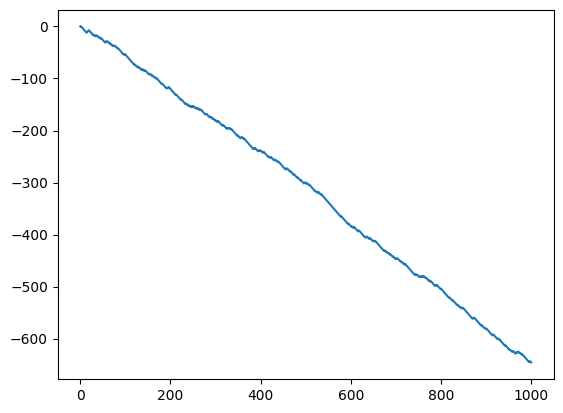

In [ ]:
sns.lineplot(cumsum)

print(f"Bankroll = {cumsum[-1]}")
print(f"E[Bankroll] = {1000.0 * (36 * PROB[0] + 28 * PROB[1] - 34) / 38.0}")

The expected value of the total payoff in this case is given by:

$E[P]= \frac{36r + 28b - 34}{38}$

&nbsp;


&nbsp;
the optimal $(r,b)$ set is (1,0) as betting red always has a positive payoff


3 \) Plotting a Histogram containing the final bankroll of 1000 players who have each played 1000 rounds:

In [ ]:
sum_arr = [0 for _ in range(N)]
for i in range(N):
  acc : int = 0
  for game in range(GAMES):
    acc += play()
  sum_arr[i] = acc

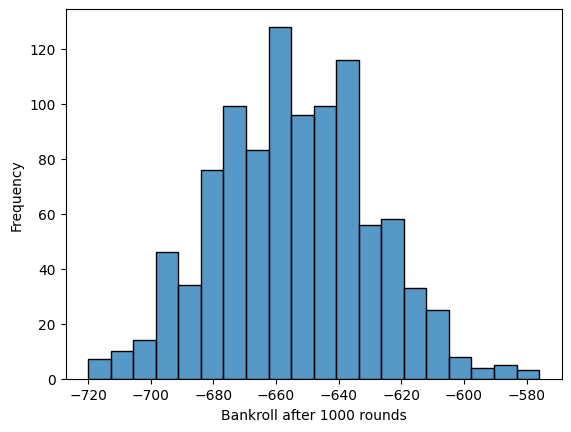

In [ ]:
sns.histplot(sum_arr)
plt.xlabel("Bankroll after 1000 rounds")
plt.ylabel("Frequency")
plt.show()

4 \) CLT Verification

Computing the theoretical mean and standard deviation

In [ ]:
def theoretical_mean(r,b) -> float:
  return 1000.00 * (36 * r + 28 * b - 34) / 38.0

def theoretical_std(r,b) -> float:
  return (1000.00 * (1-((2*(16*(r+b)+2)/38)-1)**2))**0.5

In [ ]:
print(f"Theoretical Mean: {theoretical_mean(PROB[0], PROB[1])}")
print(f"Theoretical Standard Deviation: {theoretical_std(PROB[0], PROB[1])}")

Theoretical Mean: -652.6315789473683
Theoretical Standard Deviation: 24.242541760816476


&nbsp;

Plotting a scaled version of the Bankroll Histogram (to convert it into probability density) with the corresponding Normal distribution

&nbsp;


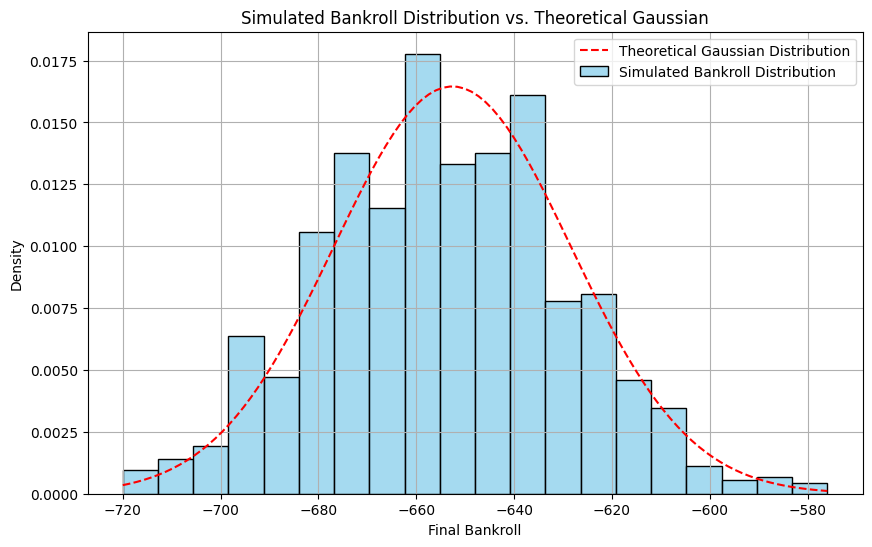

In [ ]:
theoretical_mu = theoretical_mean(PROB[0], PROB[1])
theoretical_sigma = theoretical_std(PROB[0], PROB[1])

plt.figure(figsize=(10, 6))
sns.histplot(sum_arr, stat='density', label='Simulated Bankroll Distribution', color='skyblue')            #Scaling the Histogram Plot to convert it into probability density

x = np.linspace(min(sum_arr), max(sum_arr), 100)
plt.plot(x, norm.pdf(x, theoretical_mu, theoretical_sigma), color='red', linestyle='--', label='Theoretical Gaussian Distribution')

plt.title('Simulated Bankroll Distribution vs. Theoretical Gaussian')
plt.xlabel('Final Bankroll')
plt.ylabel('Density')
plt.legend()
plt.grid(True)
plt.show()

As we can see above, the simulation closely matches theory

#Part B: Quality Control (Sampling Distributions)

Initialising parameters of the distribution

In [ ]:
mu_true = 1000
sigma_true = 5


&nbsp;

1 \) Generating a population to sample from

&nbsp;


In [ ]:
N = 100_000
population = np.random.normal(mu_true, sigma_true, N)

&nbsp;

2 \) Sampling Simulation

&nbsp;


Initialising experiment parameters

In [ ]:
n = 1000       # sample size
K = 10000         # number of experiments

Computing sample variance

In [ ]:
sample_variances = []

for _ in range(K):
    sample = np.random.choice(population, size=n, replace=False)
    S2 = np.var(sample, ddof=1)  # unbiased
    sample_variances.append(S2)

sample_variances = np.array(sample_variances)

&nbsp;

3 \) The Chi-Square Check

&nbsp;


Transformation of sample variance

In [ ]:
Y = (n-1) * sample_variances / (sigma_true)**2


Plotting a Histogram of transformed variance values

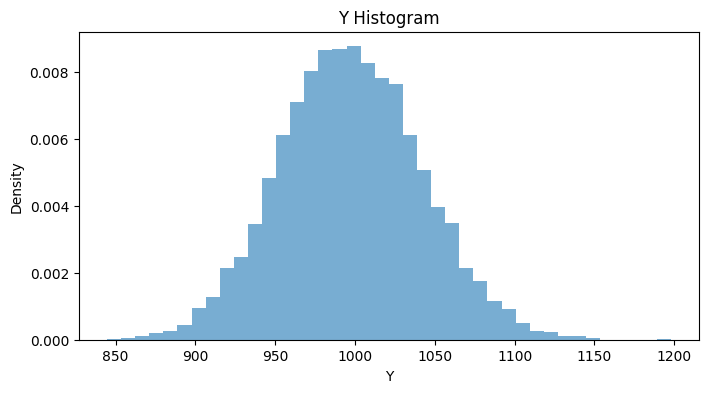

In [ ]:
plt.figure(figsize=(8,4))
plt.hist(Y, bins=40, density=True, alpha=0.6, label="Simulation")
plt.title("Y Histogram")
plt.xlabel("Y")
plt.ylabel("Density")
plt.show()


&nbsp;

4 \) Theoretical Overlay

&nbsp;


Overlaying the theoretical pdf of the Chi-Square distribution with $n-1$ degrees of freedom on $Y$'s histogram

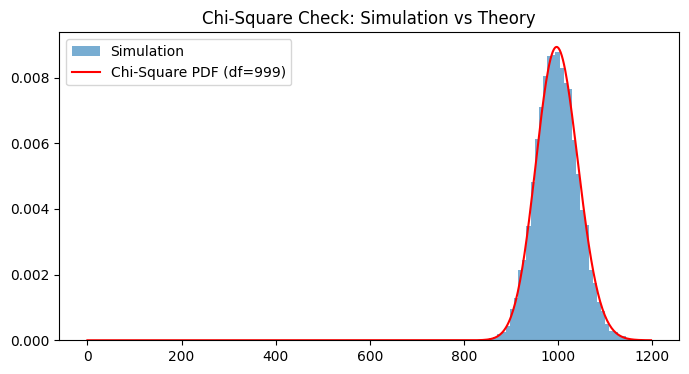

In [ ]:
x = np.linspace(0, Y.max(), 500)
pdf = chi2.pdf(x, df=n-1)

plt.figure(figsize=(8,4))
plt.hist(Y, bins=40, density=True, alpha=0.6, label="Simulation")
plt.plot(x, pdf, 'r', label=f"Chi-Square PDF (df={n-1})")
plt.legend()
plt.title("Chi-Square Check: Simulation vs Theory")
plt.show()


Trying out the above for different $K$ and $n$ shows that the statistic $Y$ follows the Chi-Square distribution with $n-1$ degrees of freedom.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from enum import Enum
import ipywidgets as widgets
from IPython.display import display
N : int = 1000            # players
GAMES : int = 1000        # games

PROB = [0.1, 0.2, 0.0]    # [r, b, g]
PROB[2] = 1 - (PROB[0] + PROB[1])

CASINO_DIST = [20, 16, 2]
CASINO_PROB = [float(x)/sum(CASINO_DIST) for x in CASINO_DIST]
class Color(Enum):
    RED = 0
    BLACK = 1
    GREEN = 2
def play() -> int:
    elements = [Color.RED, Color.BLACK, Color.GREEN]

    chosen  = np.random.choice(elements, p=PROB)
    outcome = np.random.choice(elements, p=CASINO_PROB)

    if outcome == chosen:
        return 1
    return -1
def simulate_one_player():
    cumsum = np.zeros(GAMES + 1)
    for game in range(1, GAMES + 1):
        cumsum[game] = cumsum[game - 1] + play()
    return cumsum
def interactive_plot(r, b):
    if r + b > 1:
        print("Invalid: r + b must be ≤ 1")
        return

    PROB[0] = r
    PROB[1] = b
    PROB[2] = 1 - (r + b)

    trajectory = simulate_one_player()

    plt.figure(figsize=(8,5))
    plt.plot(trajectory)
    plt.axhline(0, linestyle='--')
    plt.title(f"Bankroll Trajectory\nr={r:.2f}, b={b:.2f}")
    plt.xlabel("Game")
    plt.ylabel("Cumulative Winnings")
    plt.grid(True)
    plt.show()
r_slider = widgets.FloatSlider(
    value=PROB[0],
    min=0,
    max=1,
    step=0.01,
    description="r",
    continuous_update=False
)

b_slider= widgets.FloatSlider(
    value=PROB[1],
    min=0,
    max=1,
    step=0.01,
    description='b',
    continuous_update=False

)
widgets.interact(interactive_plot, r=r_slider, b=b_slider)


interactive(children=(FloatSlider(value=0.1, continuous_update=False, description='r', max=1.0, step=0.01), Fl…

<function __main__.interactive_plot(r, b)>

In [ ]:
def z_dist(mu : float, sigma : float):
  samples = [0.0 for _ in range(K)]
  for i in range(K):
      sample = np.random.normal(mu, sigma, n)
      cumsum : float = 0.0
      for s in sample:
        cumsum += (s - mu) ** 2 / (sigma ** 2)
      samples[i] = cumsum
  sns.histplot(samples)
  x = np.linspace(0, max(samples))
  plt.plot(x, chi2.pdf(x, df = n), color='red', linestyle='--', label='Theoretical Gaussian Distribution')

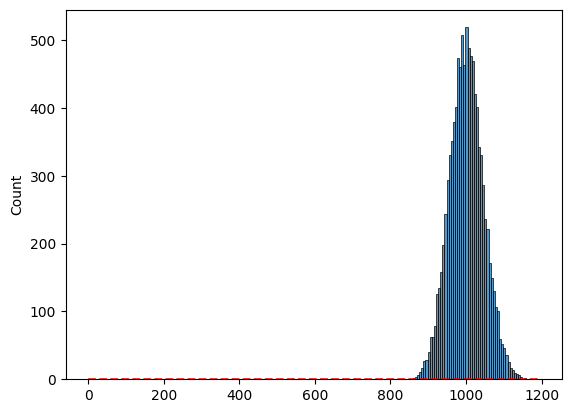

In [ ]:
z_dist(1000.0, 25.0)